# Combining parallel calculations in a fixed order

Equal size groups use boundaries taken from an evenly spaced grid:

$$
b_j=\left\lceil\frac{jN}{K}\right\rceil,
\qquad j=0,1,\ldots,K.
$$

Here, $N$ is the number of indivisible tasks, $K$ is the number of groups after limiting it to at most $N$, $j$ labels a boundary, $b_j$ is that boundary, and $\lceil\cdot\rceil$ rounds upward.

,Boundary number,Equal size boundary,Increasing work boundary
0,0,0,0
1,1,25,50
2,2,50,71
3,3,75,87
4,4,100,100


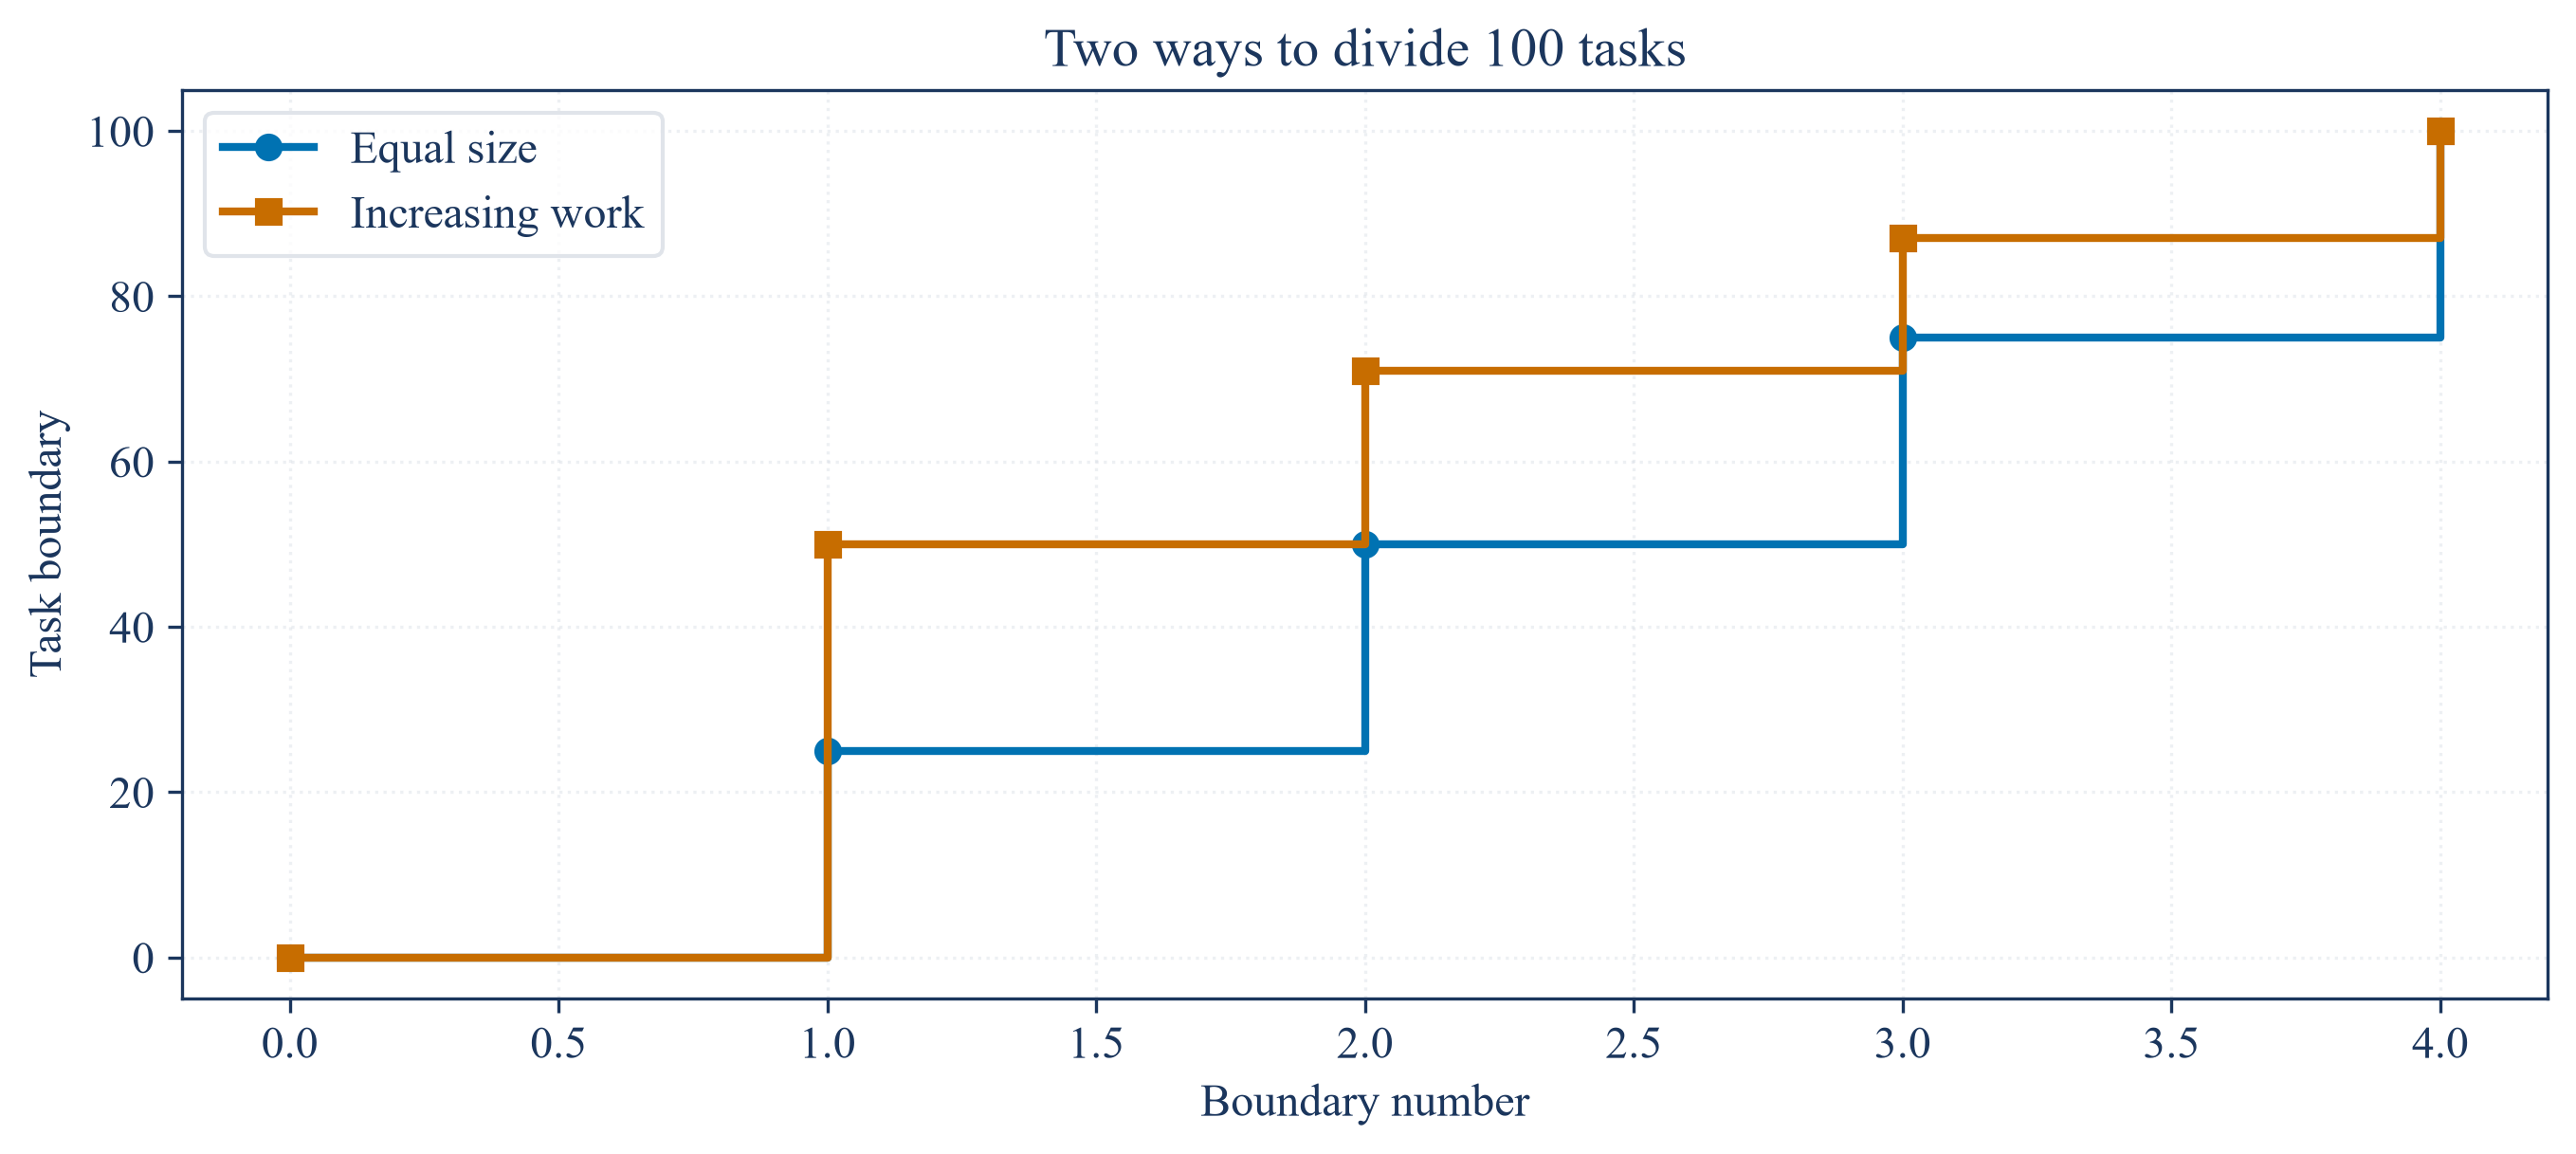

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import hashlib
import inspect
import io
import sys
import time
import warnings
import zipfile
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.hpc import linear_partitions, nested_partitions, mp_pandas_obj, parallel_run, process_jobs, process_jobs_sequential
from RiskLabAI.core import BARS, BET_SIZERS, CROSS_VALIDATORS, FEATURE_IMPORTANCE, LABELERS, PORTFOLIO_OPTIMIZERS, BaseLabeler, Registry, list_components
from RiskLabAI.controller.bars_initializer import BarsInitializerController
from RiskLabAI.controller.data_structure_controller import BAR_COLUMNS, Controller
from RiskLabAI.optimization.hrp import hrp, inverse_variance_weights

FIGURES = ROOT / "outputs" / "figures" / "32_reproducible_research_study"
TABLES = ROOT / "outputs" / "tables" / "32_reproducible_research_study"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False, float_format=compact_float_format("%.10f"))
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="tbp"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def load_french_returns():
    data_path = ROOT / "data" / "public" / "ken_french" / "49_Industry_Portfolios_daily_CSV.zip"
    expected_hash = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
    assert data_path.is_file()
    data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest().upper()
    assert data_hash == expected_hash
    with zipfile.ZipFile(data_path) as archive:
        archive_name = archive.namelist()[0]
        public_lines = archive.read(archive_name).decode("latin1").splitlines()
    header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
    end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
    raw_frame = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
    raw_frame = raw_frame.rename(columns={raw_frame.columns[0]: "Date"})
    raw_frame["Date"] = pd.to_datetime(raw_frame["Date"].astype(str), format="%Y%m%d")
    returns = raw_frame.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
    returns = returns.loc["2019-01-01":"2025-12-31"].dropna().copy()
    return returns, data_path, data_hash

def load_binance_rows(record_limit=5000):
    data_path = ROOT / "data" / "public" / "binance" / "BTCUSDT-1m-2021-01.zip"
    expected_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
    assert data_path.is_file()
    data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest().upper()
    assert data_hash == expected_hash
    columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
    raw_frame = pd.read_csv(data_path, compression="zip", header=None, names=columns, nrows=record_limit)
    times = pd.to_datetime(raw_frame["Open time"], unit="ms", utc=True).dt.tz_convert(None)
    rows = pd.DataFrame({"Date Time": times, "Price": raw_frame["Close"].astype(float), "Volume": raw_frame["Volume"].astype(float)})
    return rows, data_path, data_hash

def annualized_volatility(returns):
    return float(returns.std(ddof=1) * np.sqrt(252.0))

def maximum_drawdown(returns):
    wealth = (1.0 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

def portfolio_weights(method, covariance, correlation):
    if method == "Equal weight":
        return pd.Series(1.0 / len(covariance), index=covariance.index)
    if method == "Inverse variance":
        return pd.Series(inverse_variance_weights(covariance), index=covariance.index)
    if method == "Hierarchical risk parity":
        return hrp(covariance, correlation).reindex(covariance.index)
    raise KeyError(method)

def portfolio_record(method, weights, returns):
    path = returns @ weights.reindex(returns.columns)
    concentration = float(np.square(weights).sum())
    return {"Method": method, "Observations": len(path), "Annual mean return": float(path.mean() * 252.0), "Annual volatility": annualized_volatility(path), "Return to volatility": float(path.mean() / path.std(ddof=1) * np.sqrt(252.0)), "Maximum drawdown": maximum_drawdown(path), "Largest weight": float(weights.max()), "Weight concentration": concentration, "Effective holdings": float(1.0 / concentration)}

public_returns, french_path, french_hash = load_french_returns()
selected_returns = public_returns.iloc[:, :16].copy()
atom_count = 100
group_count = 4
linear = linear_partitions(atom_count, group_count)
nested = nested_partitions(atom_count, group_count)
boundary_table = pd.DataFrame({"Boundary number": np.arange(group_count + 1), "Equal size boundary": linear, "Increasing work boundary": nested})
save_table(boundary_table, "partition_boundaries", "Boundaries for 100 tasks and four groups.", "tab:chapter30-partition-boundaries")
display(boundary_table)

figure, axis = plt.subplots(figsize=(9.2, 4.2))
axis.step(np.arange(group_count + 1), linear, where="post", marker="o", color=palette["cyan"], linewidth=2.0, label="Equal size")
axis.step(np.arange(group_count + 1), nested, where="post", marker="s", color=palette["amber"], linewidth=2.0, label="Increasing work")
axis.set_xlabel("Boundary number")
axis.set_ylabel("Task boundary")
axis.set_title("Two ways to divide 100 tasks")
axis.grid(True, alpha=0.45)
axis.legend()
figure.tight_layout()
save_figure(figure, "partition_boundaries")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Balancing Increasing Work

When task $i$ has estimated work proportional to $i$, the next boundary follows the triangular work equation:

$$
b_j=\frac{-1+\sqrt{1+4\left(b_{j-1}^2+b_{j-1}+N(N+1)/K\right)}}{2}.
$$

Here, $i$ labels a task, its estimated work is proportional to $i$, $b_{j-1}$ is the preceding boundary, $b_j$ is the next boundary, $N(N+1)/2$ is total estimated work, and $K$ is the requested number of groups.

,Rule,Group,First task,Last task,Task count,Estimated work
0,Equal size,1,1,25,25,325
1,Equal size,2,26,50,25,950
2,Equal size,3,51,75,25,1575
3,Equal size,4,76,100,25,2200
4,Increasing work,1,1,50,50,1275
5,Increasing work,2,51,71,21,1281
6,Increasing work,3,72,87,16,1272
7,Increasing work,4,88,100,13,1222


,Rule,Tasks,Mean group work,Work standard deviation,Least group work,Greatest group work
0,Equal size,100,1262.5,806.87153,325,2200
1,Increasing work,100,1262.5,27.258026,1222,1281


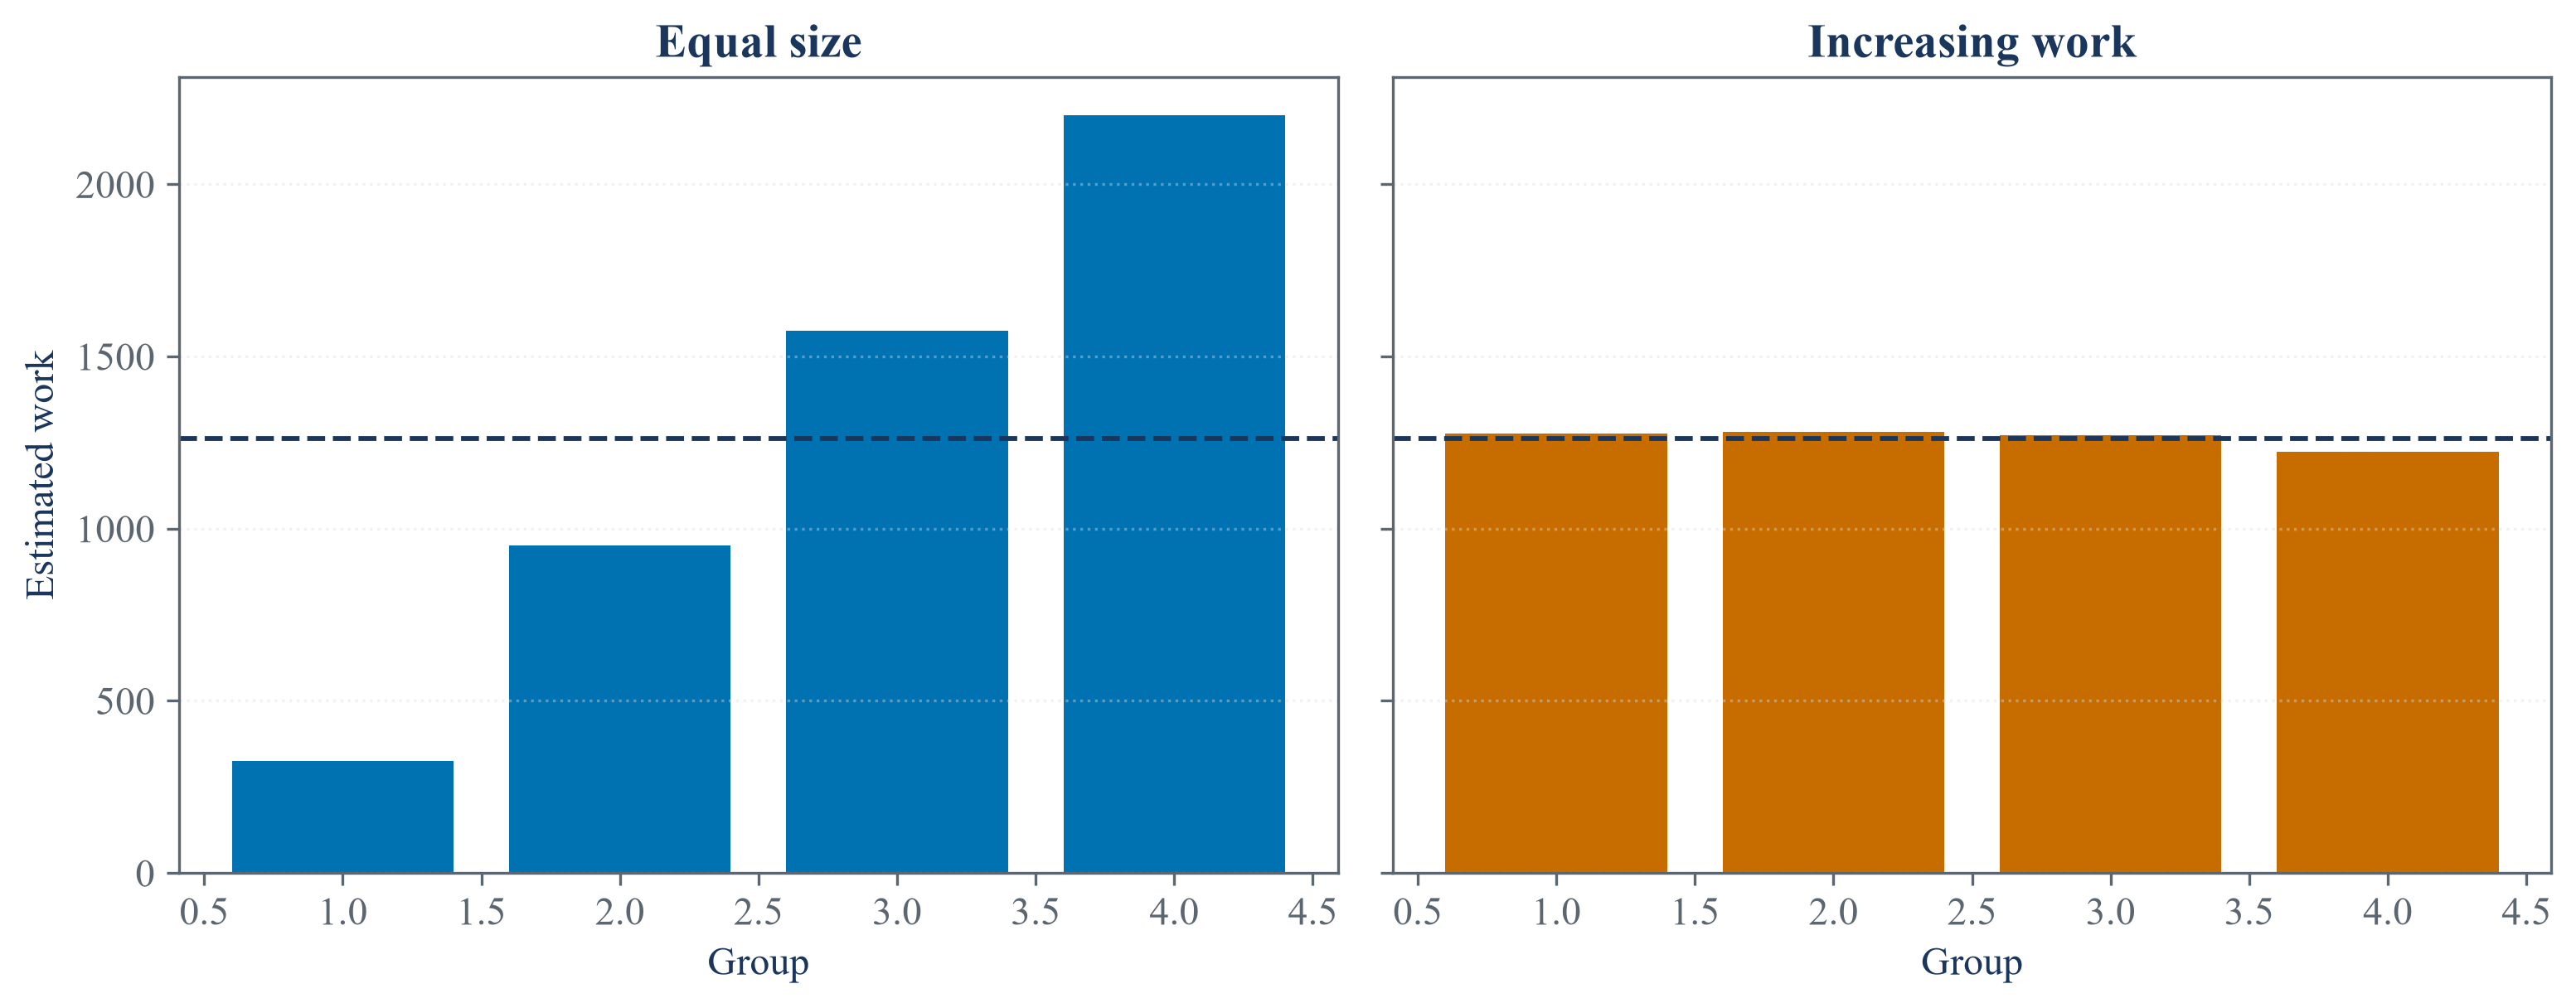

In [2]:
def group_rows(boundaries, rule):
    rows = []
    for group_number, (left, right) in enumerate(zip(boundaries[:-1], boundaries[1:]), 1):
        tasks = np.arange(left + 1, right + 1)
        rows.append({"Rule": rule, "Group": group_number, "First task": int(left + 1), "Last task": int(right), "Task count": int(right - left), "Estimated work": int(tasks.sum())})
    return rows

workload_table = pd.DataFrame(group_rows(linear, "Equal size") + group_rows(nested, "Increasing work"))
workload_summary = workload_table.groupby("Rule", as_index=False).agg({"Task count": "sum", "Estimated work": ["mean", "std", "min", "max"]})
workload_summary.columns = ["Rule", "Tasks", "Mean group work", "Work standard deviation", "Least group work", "Greatest group work"]
save_table(workload_table, "partition_workloads", "Task counts and estimated triangular work in each group.", "tab:chapter30-partition-workloads")
save_table(workload_summary, "partition_workload_summary", "Dispersion of estimated work under the two grouping rules.", "tab:chapter30-partition-summary")
display(workload_table)
display(workload_summary)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for axis, (rule, group) in zip(axes, workload_table.groupby("Rule", sort=False)):
    axis.bar(group["Group"], group["Estimated work"], color=palette["cyan"] if rule == "Equal size" else palette["amber"])
    axis.axhline(group["Estimated work"].mean(), color=palette["text"], linestyle="--", linewidth=1.4)
    axis.set_title(rule)
    axis.set_xlabel("Group")
    axis.grid(True, axis="y", alpha=0.4)
axes[0].set_ylabel("Estimated work")
figure.tight_layout()
save_figure(figure, "partition_workload_balance")

## Preserving output order in parallel calculations

A keyed result can be placed in a stable order after all tasks finish:

$$
(y_{(1)},\ldots,y_{(N)})
=\operatorname{sort}_{k}\!\left\{(k_i,y_i):i=1,\ldots,N\right\}.
$$

Here, $i$ labels the order in which a result is received, $k_i$ is its stable key, $y_i$ is its value, and $y_{(1)},\ldots,y_{(N)}$ are the values after sorting by that key.

,Result rule,Position,Task,Squared value
0,Submitted order,1,A,4
1,Submitted order,2,B,9
2,Submitted order,3,C,25
3,Submitted order,4,D,49
4,Completion order,1,D,49
5,Completion order,2,C,25
6,Completion order,3,B,9
7,Completion order,4,A,4
8,Key sorted order,1,A,4
9,Key sorted order,2,B,9


,Calculation,Elapsed seconds,Tasks
0,One task at a time,0.502623,4
1,Submitted order in parallel,0.218944,4
2,Completion order in parallel,0.202322,4


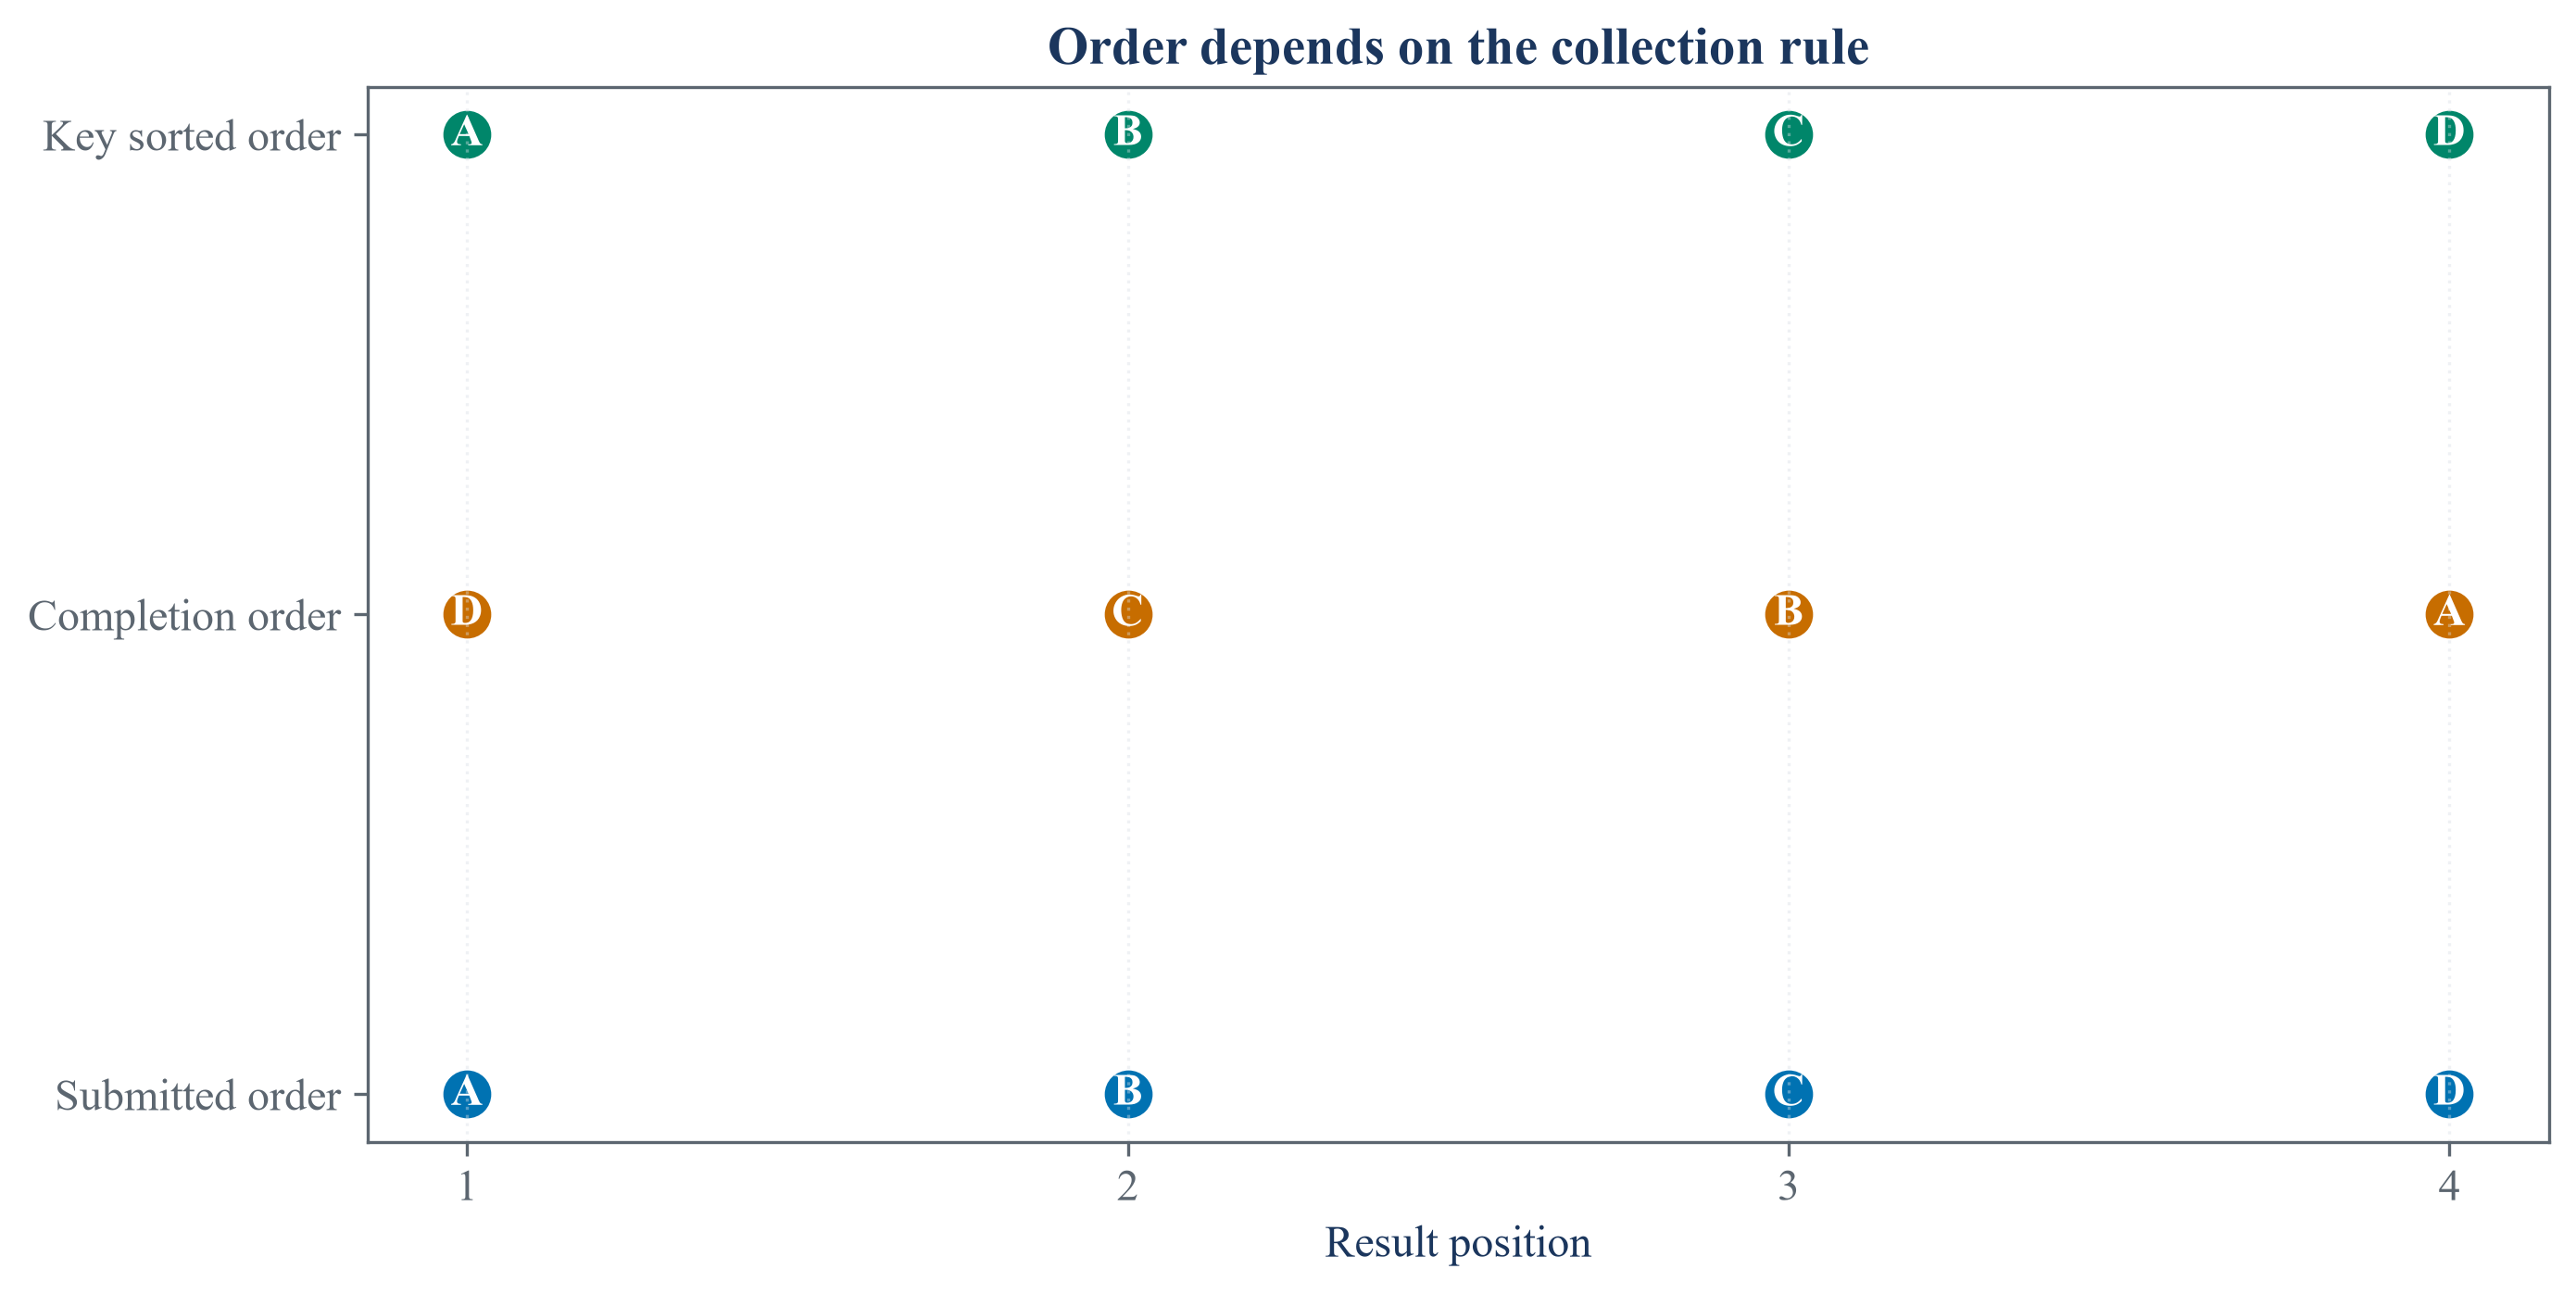

In [3]:
task_specs = [("A", 0.20, 2.0), ("B", 0.15, 3.0), ("C", 0.10, 5.0), ("D", 0.05, 7.0)]

def timed_square(specification):
    key, delay, value = specification
    time.sleep(delay)
    return key, value**2

started = time.perf_counter()
sequential_results = [timed_square(specification) for specification in task_specs]
sequential_seconds = time.perf_counter() - started

started = time.perf_counter()
with parallel_config(backend="threading"):
    submitted_results = parallel_run(timed_square, task_specs, num_cpus=4)
submitted_seconds = time.perf_counter() - started

started = time.perf_counter()
with ThreadPoolExecutor(max_workers=4) as executor:
    future_map = {executor.submit(timed_square, specification): specification[0] for specification in task_specs}
    completion_results = [future.result() for future in as_completed(future_map)]
completion_seconds = time.perf_counter() - started

key_order = {key: position for position, (key, _, _) in enumerate(task_specs)}
stable_results = sorted(completion_results, key=lambda item: key_order[item[0]])
order_rows = []
for order_name, values in [("Submitted order", submitted_results), ("Completion order", completion_results), ("Key sorted order", stable_results)]:
    for position, (key, value) in enumerate(values, 1):
        order_rows.append({"Result rule": order_name, "Position": position, "Task": key, "Squared value": value})
order_table = pd.DataFrame(order_rows)
timing_table = pd.DataFrame({"Calculation": ["One task at a time", "Submitted order in parallel", "Completion order in parallel"], "Elapsed seconds": [sequential_seconds, submitted_seconds, completion_seconds], "Tasks": [len(task_specs)] * 3})
save_table(order_table, "result_order_comparison", "The same keyed results under three presentation rules.", "tab:chapter30-result-orders")
save_table(timing_table, "small_task_timing", "Measured time for four deliberately uneven tasks on this machine.", "tab:chapter30-small-task-timing")
display(order_table)
display(timing_table)

figure, axis = plt.subplots(figsize=(9.4, 4.8))
order_names = ["Submitted order", "Completion order", "Key sorted order"]
colors = [palette["cyan"], palette["amber"], palette["green"]]
for row_number, (order_name, color) in enumerate(zip(order_names, colors)):
    values = order_table.loc[order_table["Result rule"] == order_name]
    axis.scatter(values["Position"], np.full(len(values), row_number), s=130, color=color)
    for row in values.itertuples():
        axis.text(row.Position, row_number, row.Task, ha="center", va="center", color=palette["background"], fontweight="bold")
axis.set_yticks(range(len(order_names)))
axis.set_yticklabels(order_names)
axis.set_xticks(range(1, len(task_specs) + 1))
axis.set_xlabel("Result position")
axis.set_title("Order depends on the collection rule")
axis.grid(True, axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "result_order_rules")

## Indexed Results

The indexed route combines group results and then orders the combined object by its index:

$$
Y=\operatorname{sortindex}\!\left(\operatorname{concat}(Y_1,\ldots,Y_K)\right).
$$

Here, $Y_j$ is the indexed result returned by group $j$, $K$ is the number of groups, $\operatorname{concat}$ joins those results, and $\operatorname{sortindex}$ restores increasing index order.

In [4]:
indexed_values = pd.Series(np.arange(12, dtype=float), index=pd.Index(np.arange(12), name="Observation"))

def reverse_partition(molecule, values):
    chosen = molecule[::-1]
    return pd.Series(np.square(values.loc[chosen]), index=chosen, name="Squared value")

indexed_result = mp_pandas_obj(reverse_partition, ("molecule", indexed_values.index), num_threads=1, mp_batches=3, values=indexed_values)
indexed_table = indexed_result.rename_axis("Observation").reset_index()
source_rule_table = pd.DataFrame({"Released route": ["General job collection", "Named simultaneous calculation", "Indexed table calculation"], "Observed rule": ["Completion order", "Submitted order", "Increasing index"], "Direct check": ["Source uses unordered collection", "Uneven task check preserves submission", "Reversed group output is sorted"]})
save_table(indexed_table, "indexed_sort_check", "Indexed results after group combination and final sorting.", "tab:chapter30-indexed-sort")
save_table(source_rule_table, "released_order_rules", "Ordering rules for three released calculation routes.", "tab:chapter30-released-order-rules")
display(indexed_table)
display(source_rule_table)

,Observation,Squared value
0,0,0
1,1,1
2,2,4
3,3,9
4,4,16
5,5,25
6,6,36
7,7,49
8,8,64
9,9,81


,Released route,Observed rule,Direct check
0,General job collection,Completion order,Source uses unordered collection
1,Named simultaneous calculation,Submitted order,Uneven task check preserves submission
2,Indexed table calculation,Increasing index,Reversed group output is sorted


## Timing public return calculations

The measured ratio of sequential time to simultaneous time is:

$$
S=\frac{T_{\mathrm{one}}}{T_{\mathrm{many}}}.
$$

Here, $T_{\mathrm{one}}$ is elapsed time when tasks are evaluated one at a time, $T_{\mathrm{many}}$ is elapsed time under the chosen simultaneous setting, and $S$ is a measured ratio for this task and machine rather than a universal guarantee.

,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Start date,2019-01-02
3,End date,2025-12-31
4,Complete observations,1760
5,Industries,16
6,File SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...


,Industry,Observations,Annual mean return,Annual volatility,Mean rolling volatility,Greatest rolling volatility
0,Agric,1760,0.189802,0.289434,0.274429,0.756894
1,Food,1760,0.047579,0.167198,0.154077,0.481162
2,Soda,1760,0.12242,0.191464,0.173385,0.574366
3,Beer,1760,0.063215,0.1975,0.175403,0.641972
4,Smoke,1760,0.172964,0.22345,0.206941,0.607746
5,Toys,1760,0.085651,0.349448,0.332061,0.744766
6,Fun,1760,0.16612,0.306786,0.286154,0.654879
7,Books,1760,0.127718,0.246486,0.231317,0.650985
8,Hshld,1760,0.081614,0.182269,0.164207,0.564325
9,Clths,1760,0.072235,0.303602,0.284404,0.715579


,Repetition,One task at a time seconds,Simultaneous seconds,Measured ratio
0,1,0.004712,0.012422,0.379331
1,2,0.004243,0.011791,0.359876
2,3,0.004017,0.012294,0.326785
3,4,0.004225,0.011712,0.360757
4,5,0.003916,0.011678,0.335309


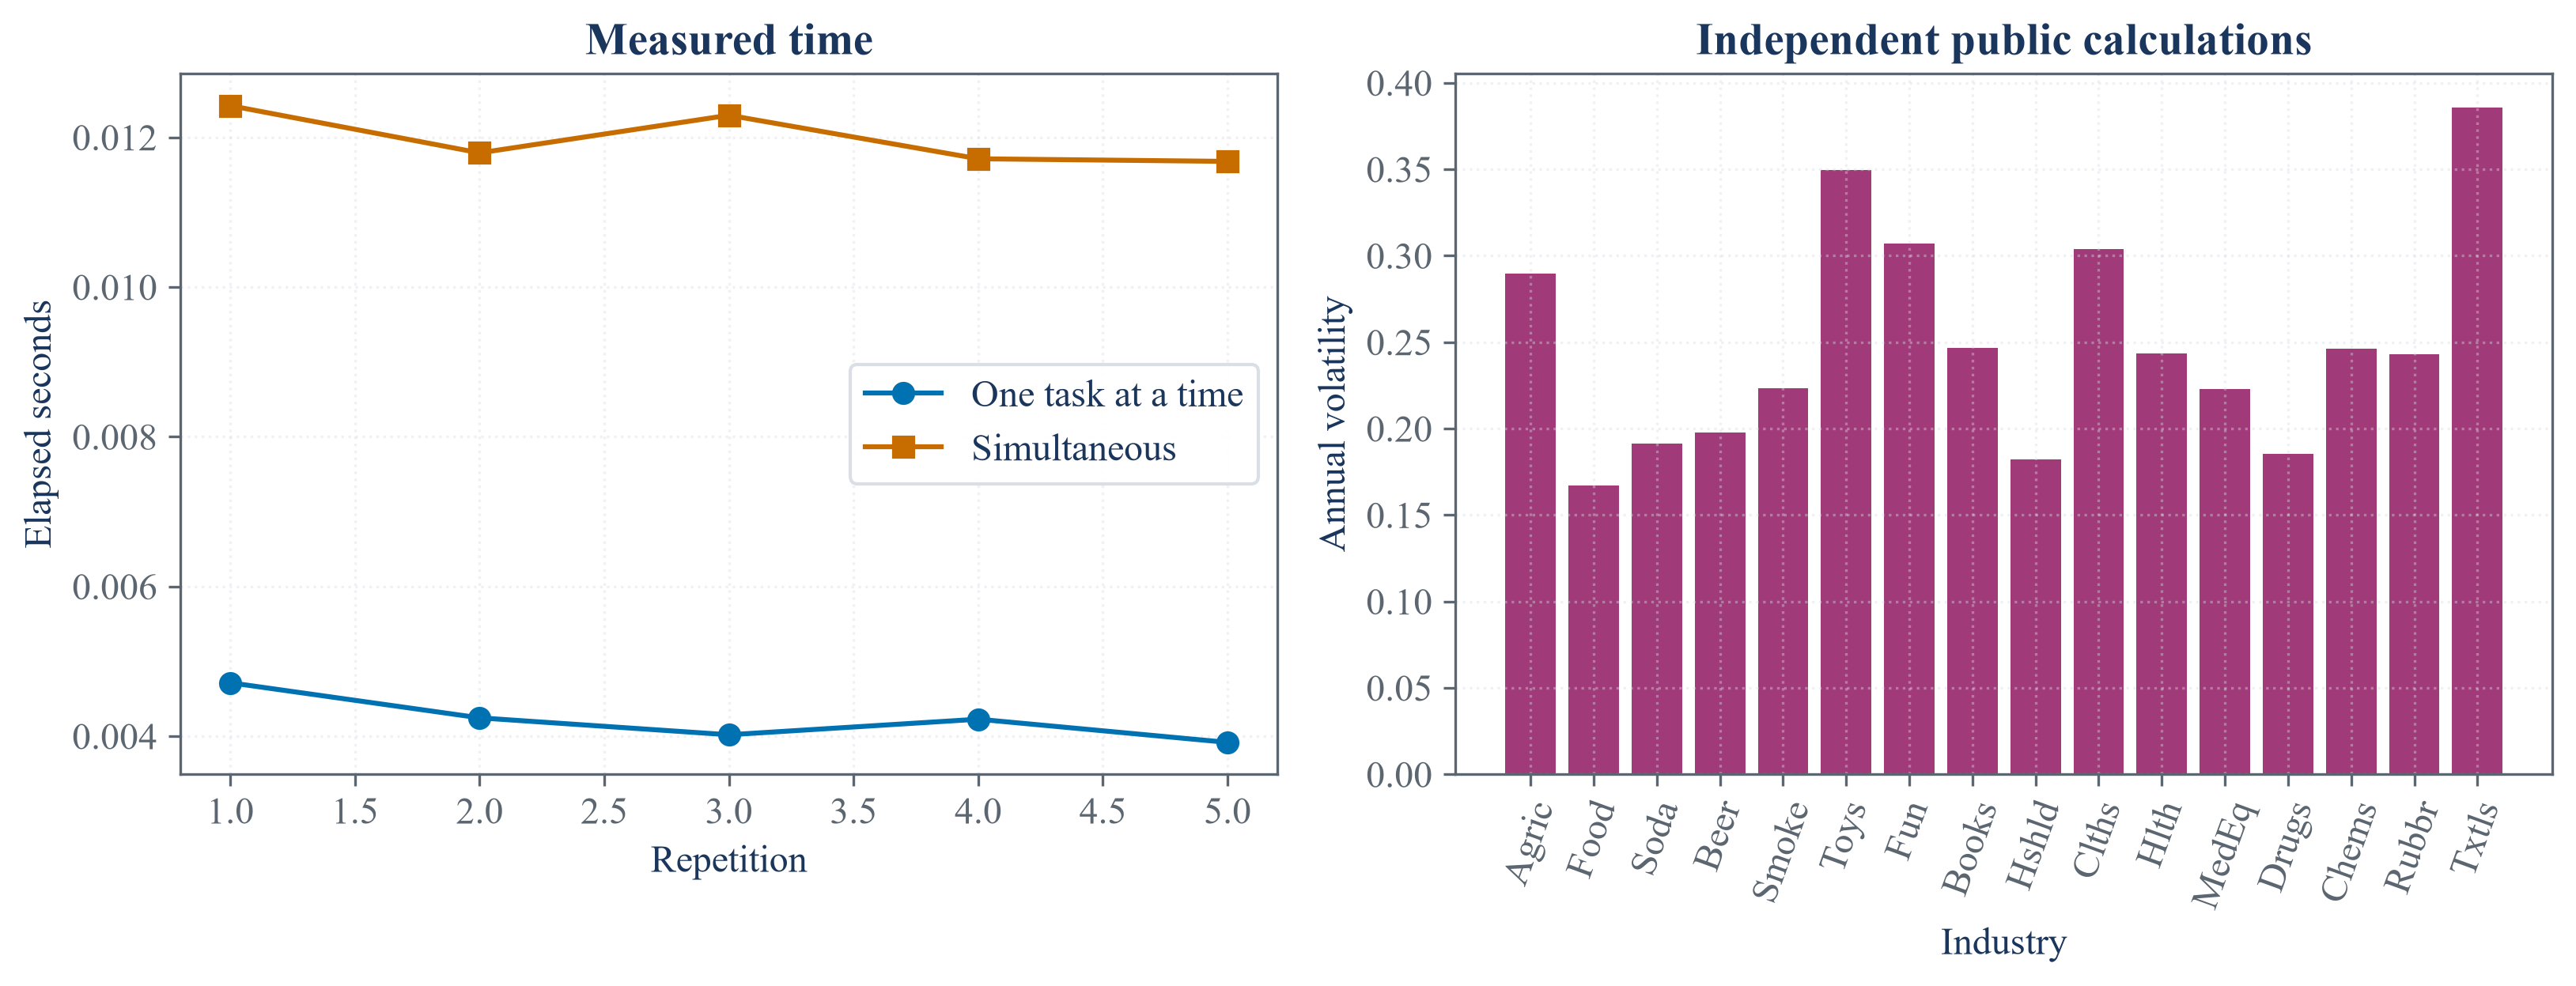

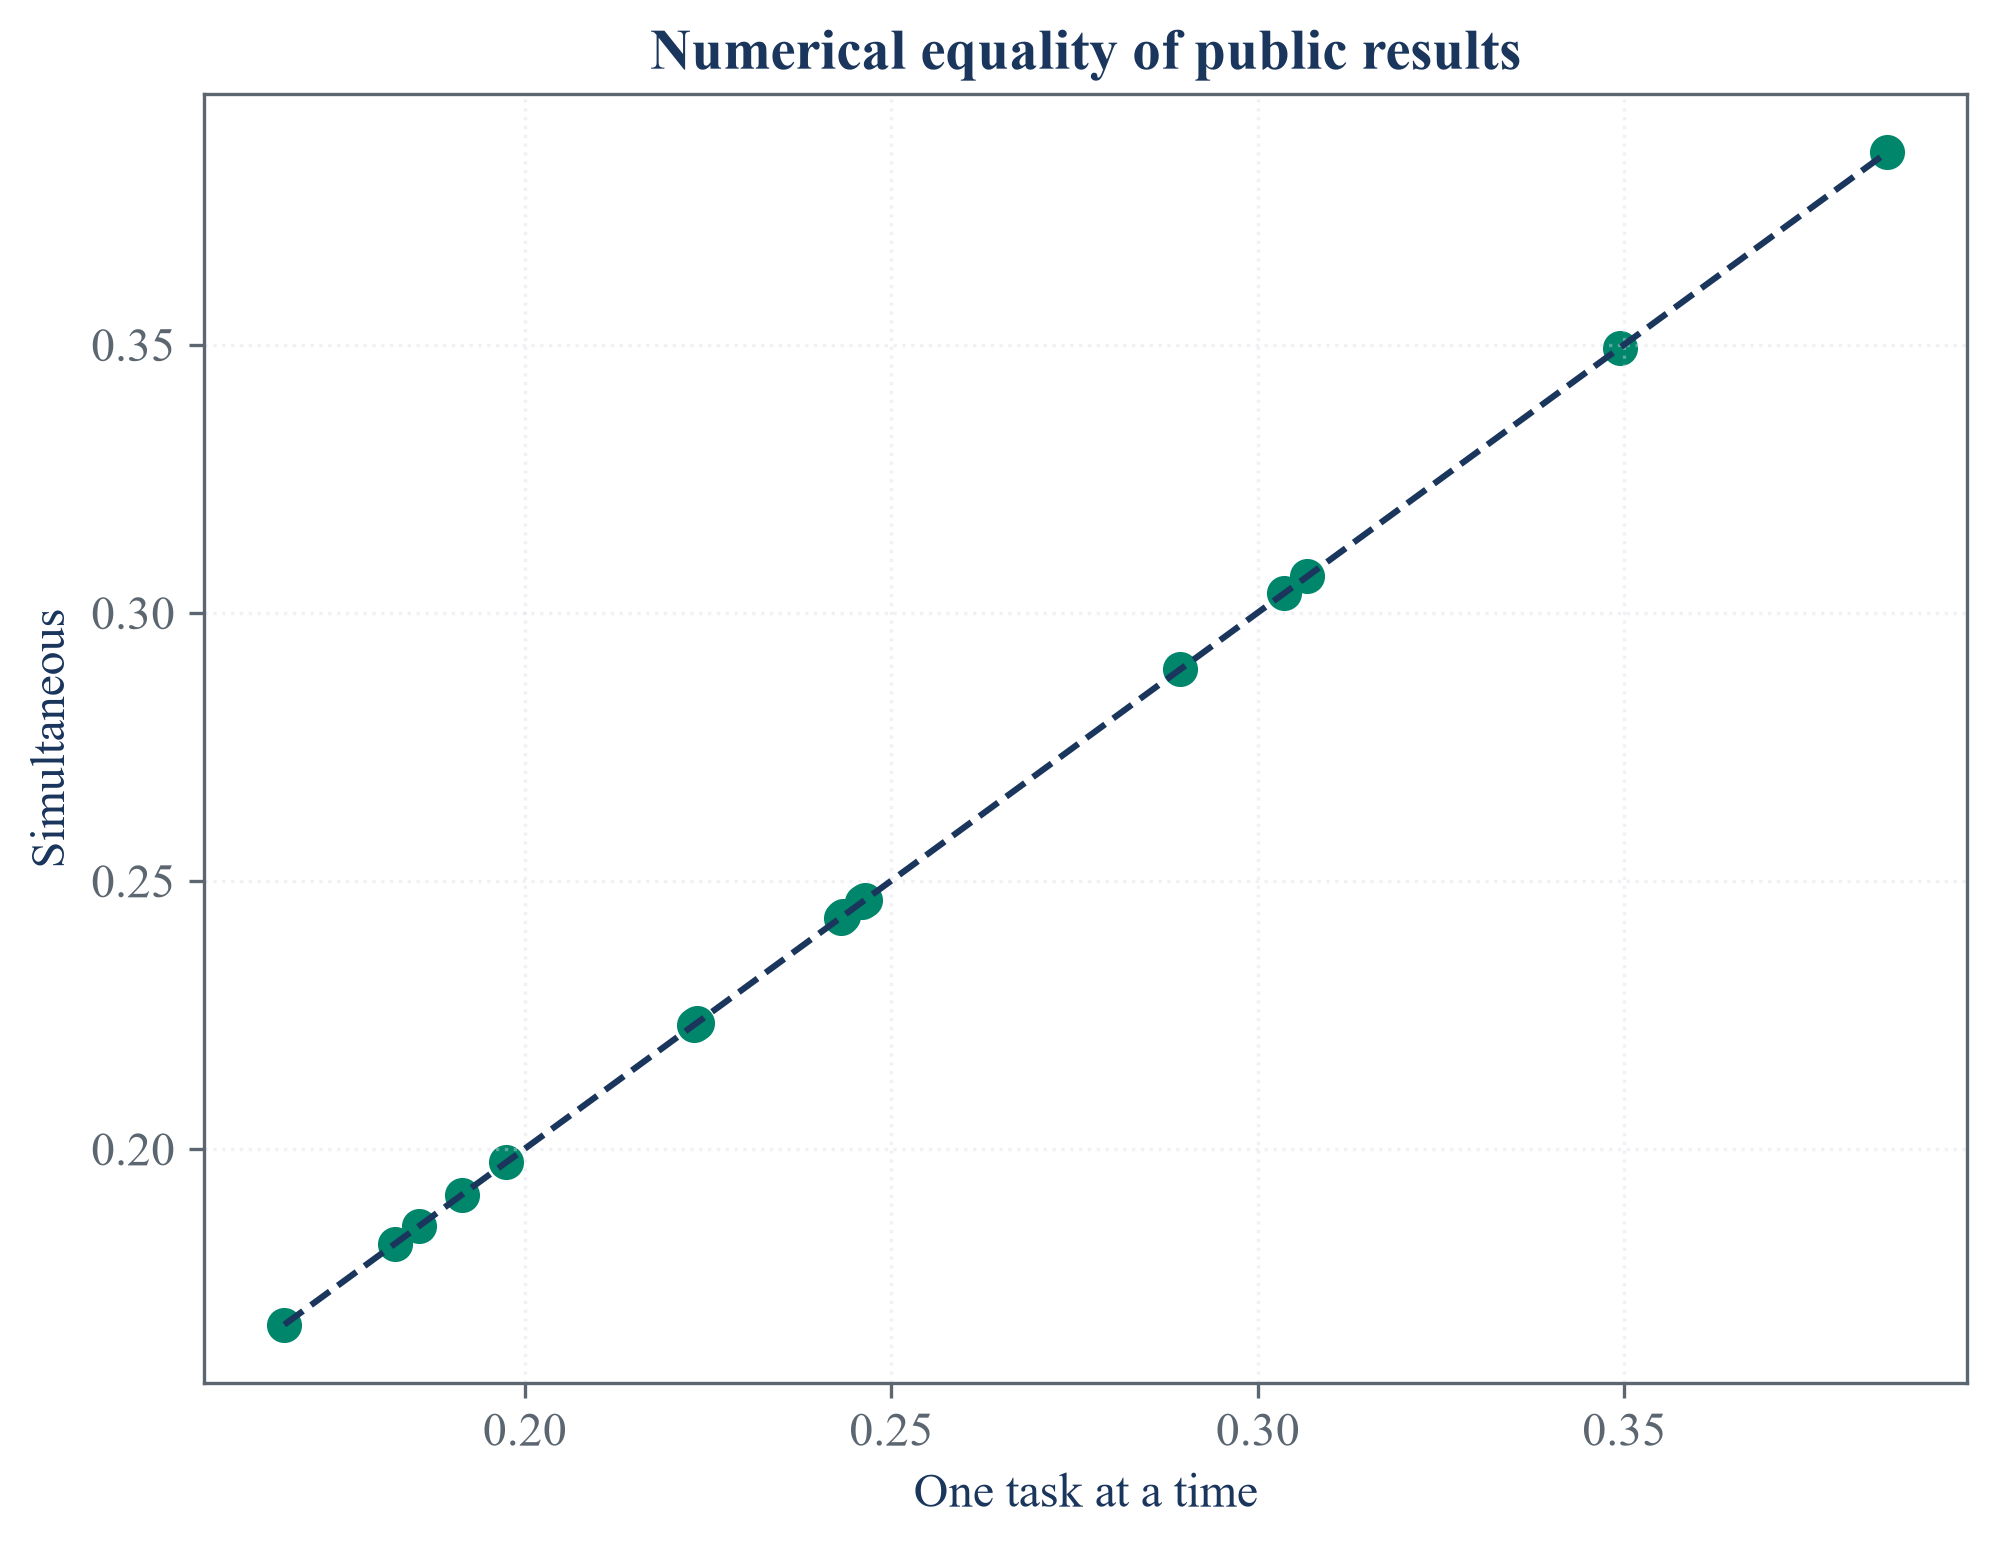

In [5]:
def asset_summary(asset):
    values = selected_returns[asset]
    rolling = values.rolling(63).std().dropna() * np.sqrt(252.0)
    return {"Industry": asset, "Observations": len(values), "Annual mean return": values.mean() * 252.0, "Annual volatility": values.std(ddof=1) * np.sqrt(252.0), "Mean rolling volatility": rolling.mean(), "Greatest rolling volatility": rolling.max()}

asset_names = list(selected_returns.columns)
timing_rows = []
sequential_public = None
parallel_public = None
for repetition in range(1, 6):
    started = time.perf_counter()
    sequential_public = [asset_summary(asset) for asset in asset_names]
    one_seconds = time.perf_counter() - started
    started = time.perf_counter()
    with parallel_config(backend="threading"):
        parallel_public = parallel_run(asset_summary, asset_names, num_cpus=4)
    many_seconds = time.perf_counter() - started
    timing_rows.append({"Repetition": repetition, "One task at a time seconds": one_seconds, "Simultaneous seconds": many_seconds, "Measured ratio": one_seconds / many_seconds})
public_summary = pd.DataFrame(parallel_public)
public_timing = pd.DataFrame(timing_rows)
public_provenance = pd.DataFrame({"Field": ["Archive", "Provider", "Start date", "End date", "Complete observations", "Industries", "File SHA256"], "Value": [french_path.name, "Kenneth R. French Data Library", str(selected_returns.index.min().date()), str(selected_returns.index.max().date()), len(selected_returns), len(asset_names), french_hash]})
save_table(public_provenance, "parallel_data_provenance", "Public return source used for the calculation timing check.", "tab:chapter30-parallel-provenance")
save_table(public_summary, "public_return_calculations", "Public return summaries calculated separately for sixteen industries.", "tab:chapter30-public-calculations")
save_table(public_timing, "public_calculation_timing", "Five measured calculation times under the two execution settings.", "tab:chapter30-public-timing")
display(public_provenance)
display(public_summary)
display(public_timing)

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.3))
axes[0].plot(public_timing["Repetition"], public_timing["One task at a time seconds"], marker="o", color=palette["cyan"], label="One task at a time")
axes[0].plot(public_timing["Repetition"], public_timing["Simultaneous seconds"], marker="s", color=palette["amber"], label="Simultaneous")
axes[0].set_xlabel("Repetition")
axes[0].set_ylabel("Elapsed seconds")
axes[0].set_title("Measured time")
axes[0].legend()
axes[1].bar(public_summary["Industry"], public_summary["Annual volatility"], color=palette["violet"])
axes[1].set_xlabel("Industry")
axes[1].set_ylabel("Annual volatility")
axes[1].set_title("Independent public calculations")
axes[1].tick_params(axis="x", rotation=70)
for axis in axes:
    axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "public_calculation_timing_and_results")

sequential_frame = pd.DataFrame(sequential_public).sort_values("Industry").reset_index(drop=True)
parallel_frame = pd.DataFrame(parallel_public).sort_values("Industry").reset_index(drop=True)
figure, axis = plt.subplots(figsize=(6.8, 5.3))
axis.scatter(sequential_frame["Annual volatility"], parallel_frame["Annual volatility"], color=palette["green"], s=55)
bounds = [min(sequential_frame["Annual volatility"].min(), parallel_frame["Annual volatility"].min()), max(sequential_frame["Annual volatility"].max(), parallel_frame["Annual volatility"].max())]
axis.plot(bounds, bounds, color=palette["text"], linestyle="--")
axis.set_xlabel("One task at a time")
axis.set_ylabel("Simultaneous")
axis.set_title("Numerical equality of public results")
axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "public_calculation_equality")

## Tests

In [6]:
assert linear.tolist() == [0, 25, 50, 75, 100]
assert nested.tolist() == [0, 50, 71, 87, 100]
assert workload_table.groupby("Rule")["Task count"].sum().eq(atom_count).all()
equal_work_std = workload_summary.loc[workload_summary["Rule"] == "Equal size", "Work standard deviation"].iloc[0]
nested_work_std = workload_summary.loc[workload_summary["Rule"] == "Increasing work", "Work standard deviation"].iloc[0]
assert nested_work_std < equal_work_std
assert submitted_results == sequential_results
assert stable_results == sequential_results
assert sorted(completion_results) == sorted(sequential_results)
assert indexed_result.index.is_monotonic_increasing
assert "imap_unordered" in inspect.getsource(process_jobs)
assert "sort_index" in inspect.getsource(mp_pandas_obj)
pd.testing.assert_frame_equal(sequential_frame, parallel_frame)
assert len(public_summary) == 16
assert len(public_timing) == 5
display(pd.DataFrame({"Test": ["Equal size boundaries", "Increasing work boundaries", "Every task included", "Increasing work balance", "Submitted order", "Key sorted order", "Same keyed results", "Indexed sorting", "Completion collection source", "Public numerical equality", "Repeated timing"], "Passed": [True] * 11}))

,Test,Passed
0,Equal size boundaries,True
1,Increasing work boundaries,True
2,Every task included,True
3,Increasing work balance,True
4,Submitted order,True
5,Key sorted order,True
6,Same keyed results,True
7,Indexed sorting,True
8,Completion collection source,True
9,Public numerical equality,True
